<a href="https://colab.research.google.com/github/Ruba-Alharbi/soft-moe-explained/blob/main/ADL_Soft_MoE_Presentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From Sparse to Soft Mixtures of Experts (Soft MoE)

**Purpose:** explain how **Sparse** and **Soft** Mixture of Experts work, based on the paper
*Puigcerver, Riquelme, Mustafa & Houlsby (2024). From Sparse to Soft Mixtures of Experts. ICLR 2024.*


---
# PART I

## 1. Meet the cast: the words we will use

*Terms as used in the paper (Sections 1, 2.1, 2.2). Pictures and analogies are ours.*

Before the story, here are the eight words that come back again and again in this talk. Each card has a one-line meaning and an everyday "Like:" to help it stick.

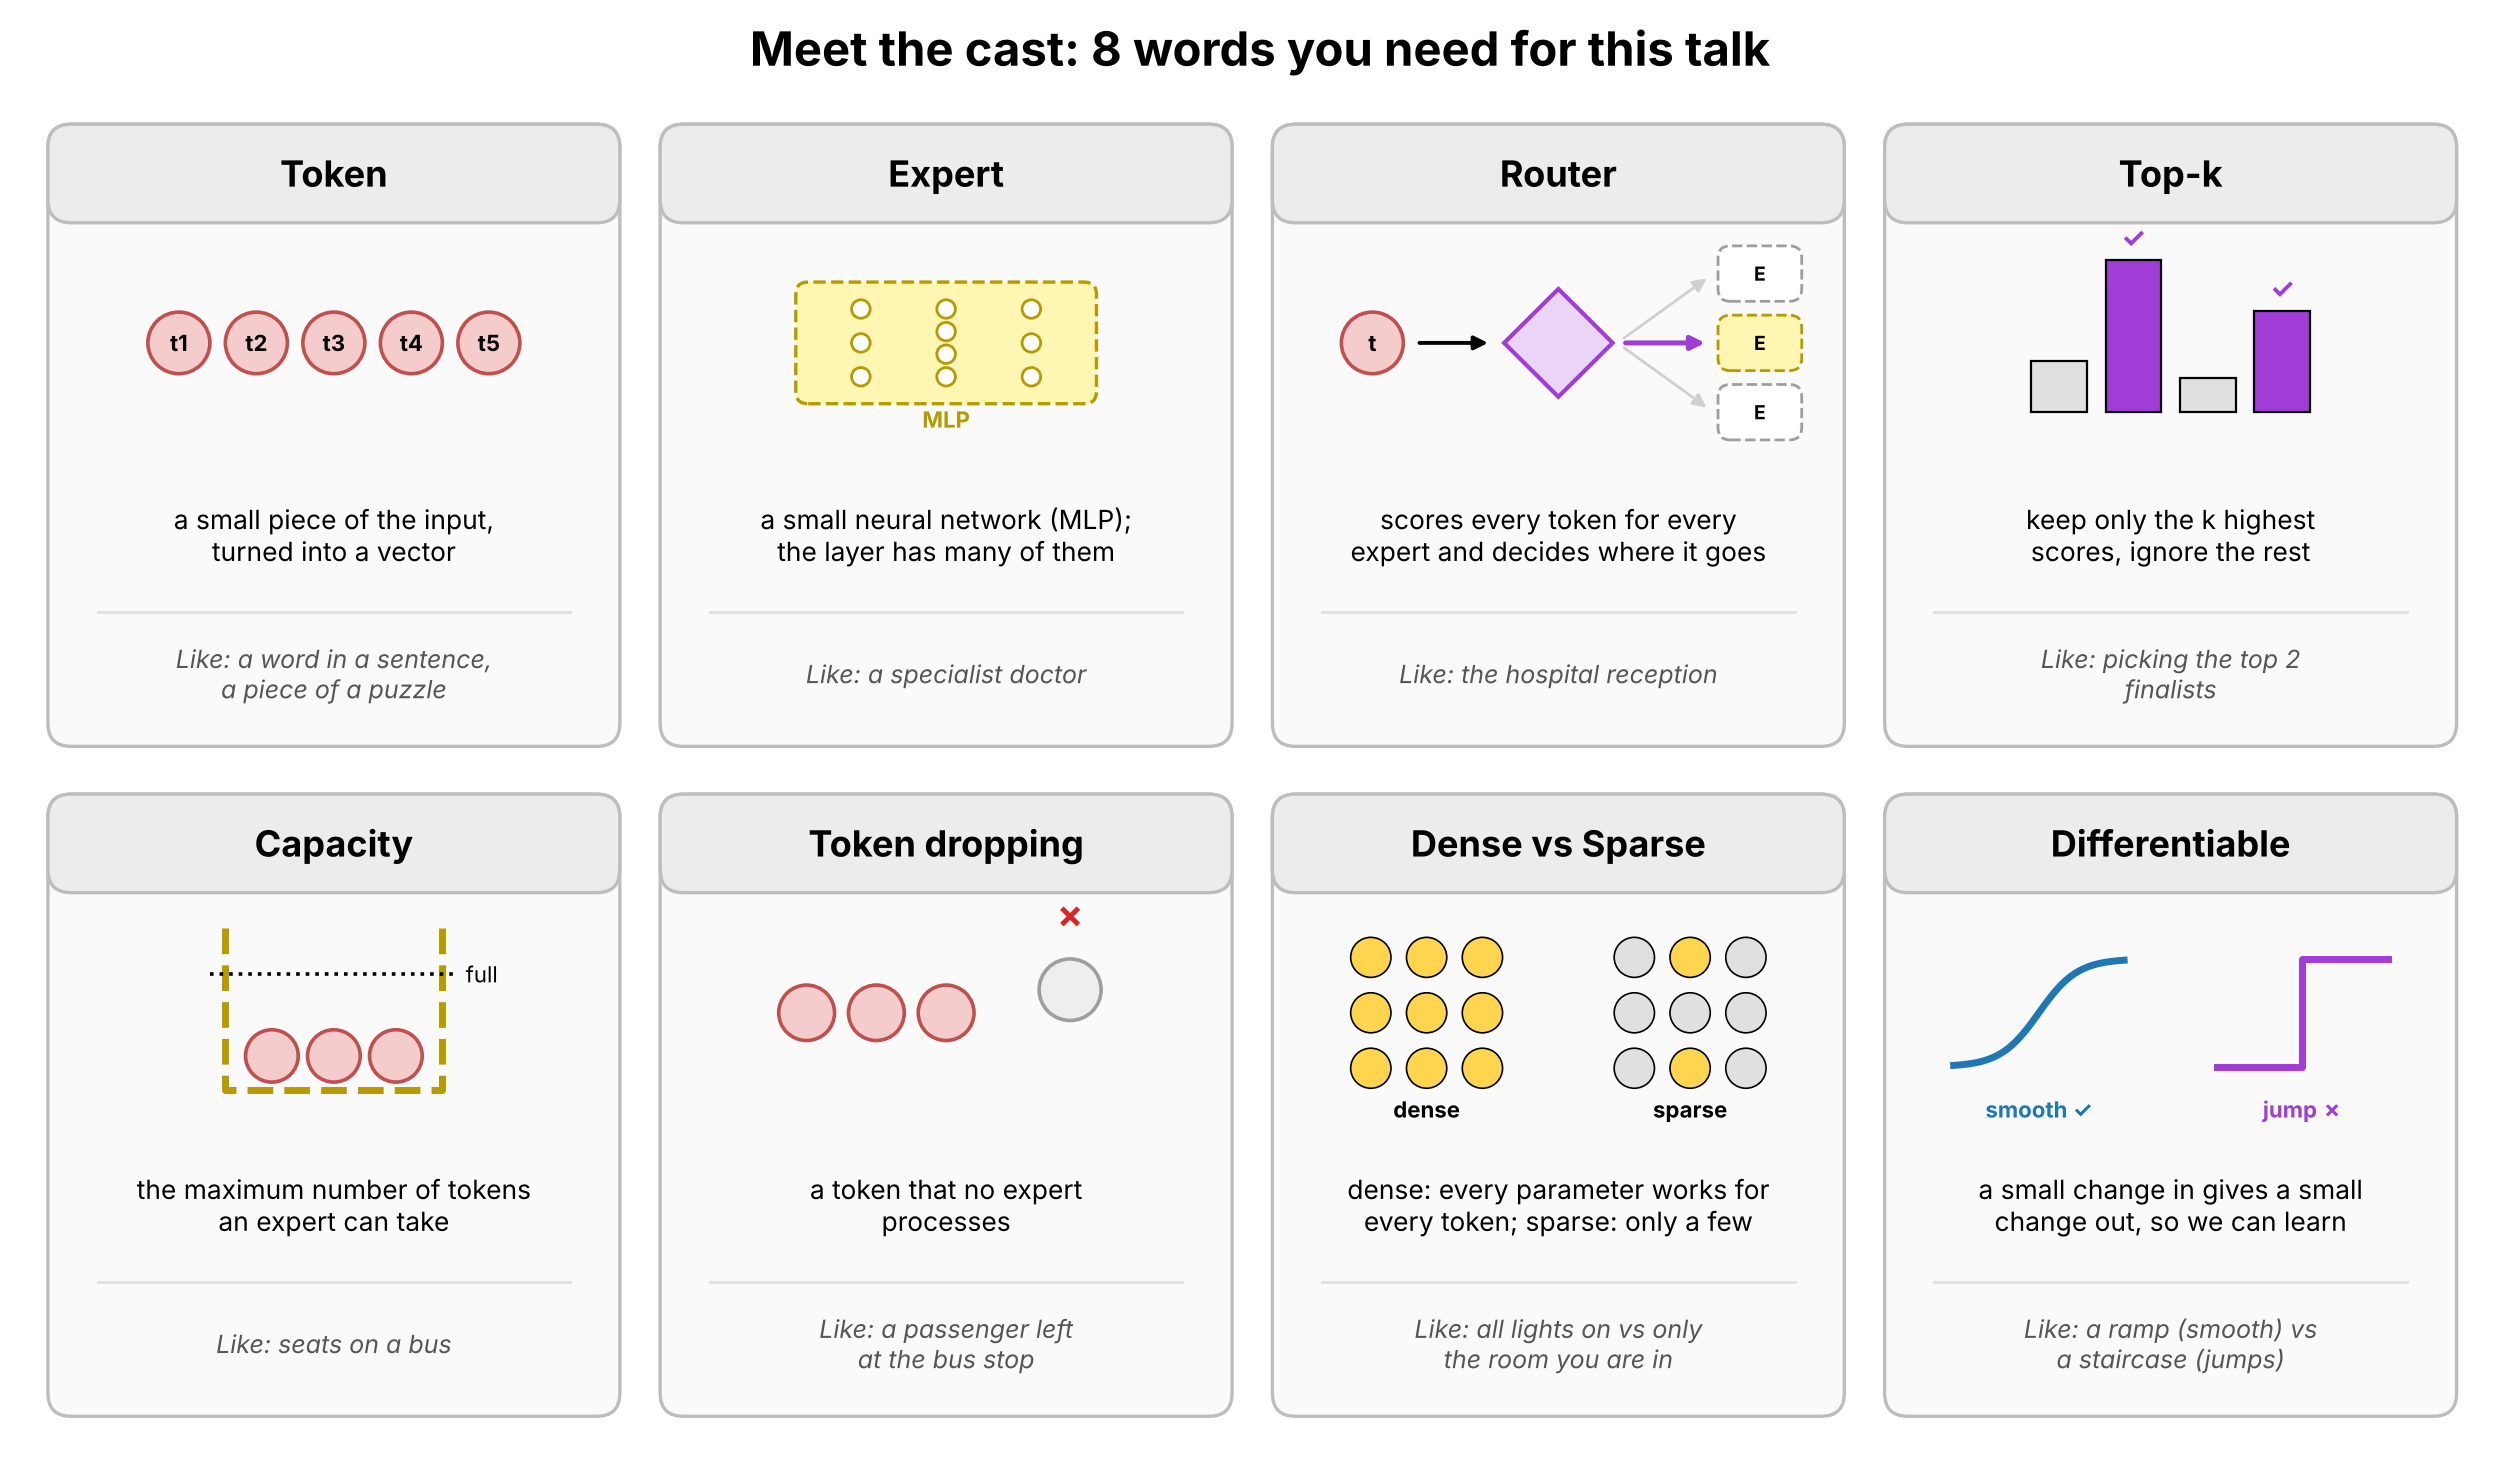

**[our illustration]**


## 2. What is a Mixture of Experts?

*Paper: Section 1, Section 2.1 (and footnote 1), Section 2.3, Section 6.*

**One sentence:** an MoE layer replaces one big MLP with **many smaller MLPs (experts)**, and a **router** decides which experts each token uses.

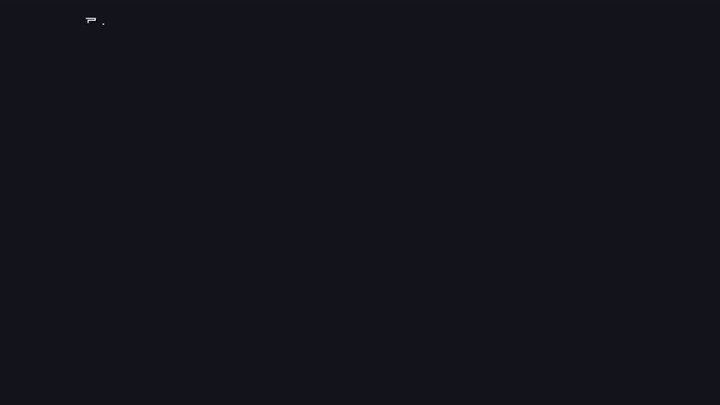

**Animation 1 · From a dense block to an MoE block** *[our illustration, toy example]*

* **Dense block:** attention, then one MLP. Every parameter of the MLP works for every token.
* **MoE block:** the MLP is replaced by several experts, with **one router per layer** in front of them.
* The router sends each token to its **top-1 expert** only (yellow). The other experts do no work for that token.
* Different tokens can go to different experts. An expert that no token picked (E4) stays idle.

**Where do the MoE layers go?**

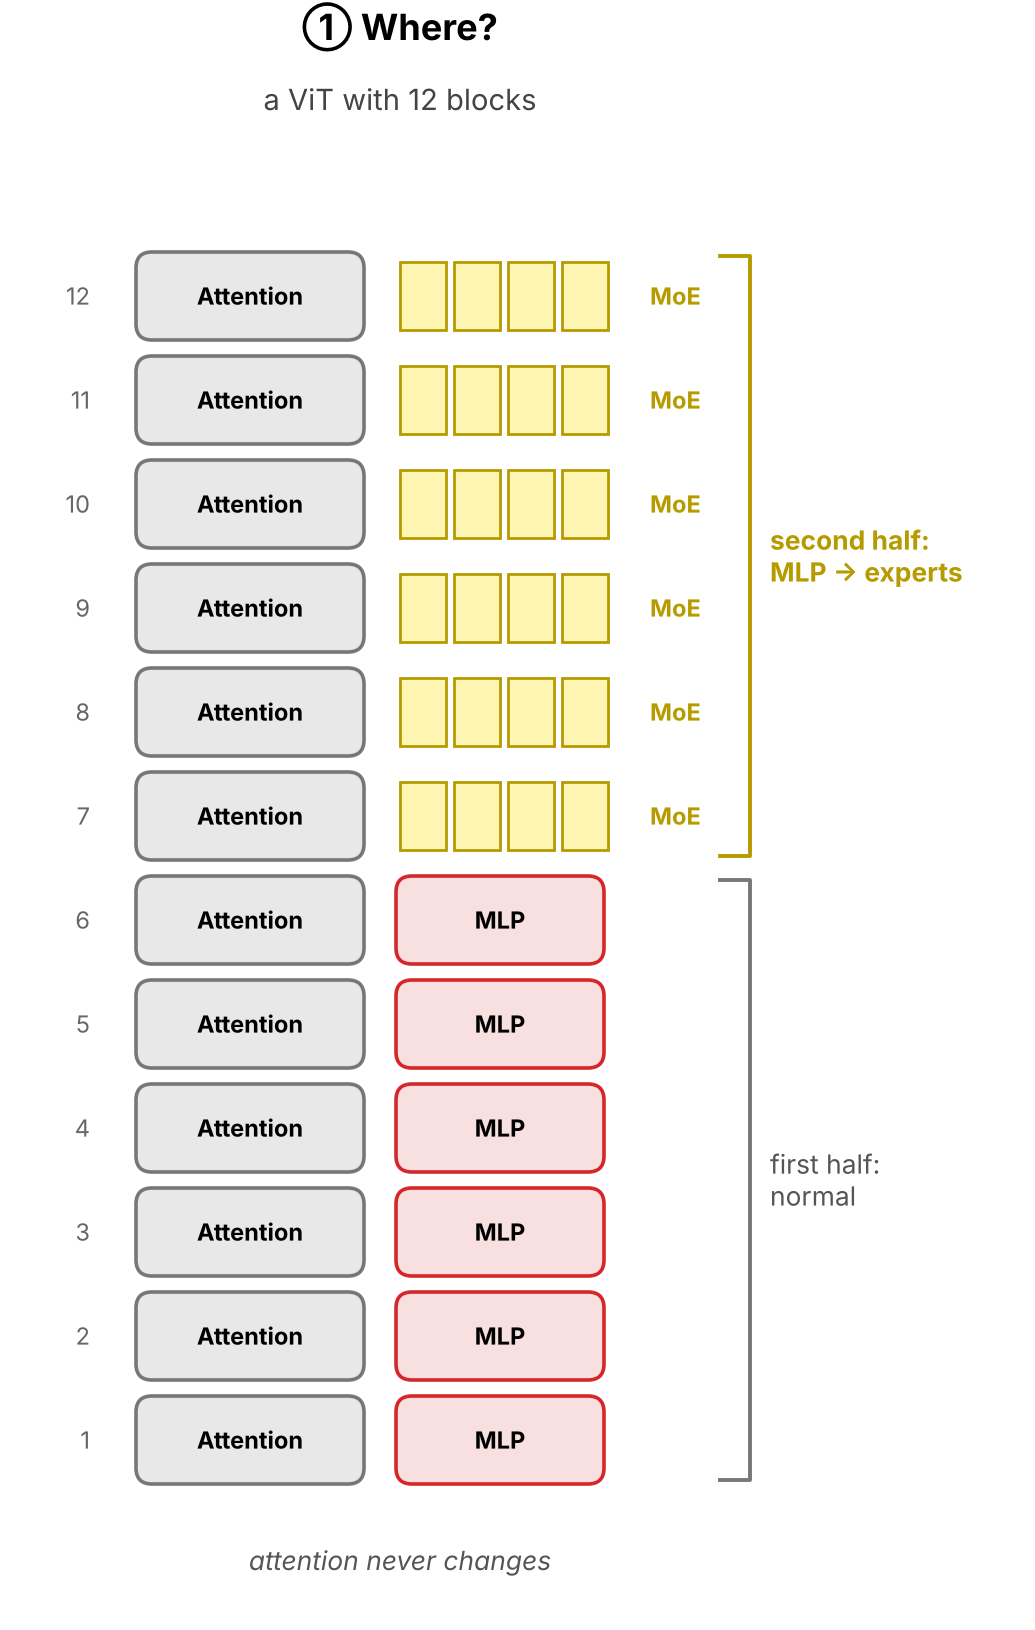

**[our illustration]** In a 12-block ViT, the last 6 blocks swap their MLP for experts. Attention never changes.

**What the paper says about it:**
* Experts "are usually MLPs" (Section 1); all experts apply **the same function with different parameters** (footnote 1).
* MoE layers **replace a subset of the MLP blocks**, typically **the second half** of them (Section 2.1). Self-attention does not change.
* The win (Abstract): sparse MoEs **"scale model capacity without significant increases in training or inference costs."**

**Scientific caution:** saving compute is not saving memory. All experts must be stored; with many experts the model is split across devices (Section 2.3) and "the memory requirements of the model can grow large" (Section 6).

## 3. Why do we need MoE?

*Paper: Abstract, Section 1, Section 2.2.*

* Bigger models perform better (Kaplan et al., 2020; Hoffmann et al., 2022; Zhai et al., 2022a), but in a **dense** model the compute grows with the number of parameters.
* MoE **decouples model size from compute cost**: we can add experts (more parameters) while each token still uses only one or two of them.

> **The key question:** if each token only uses a few experts, *how do we decide which ones?*
> This decision is called **routing**, and it is the whole topic of this paper.

**What the paper says about routing so far:** almost all existing routing methods are *"discrete in nature, and thus non-differentiable"* (Section 2.2). Sparse MoEs suffer from **training instability, token dropping, inability to scale the number of experts, and ineffective finetuning** (Abstract). Section 5 below shows where these problems come from.


## 4. In this paper, tokens are image patches

*Paper: Section 2.1 (notation), Figure 1, Sections 3.1 and 3.3.*

All the paper's main experiments use **Vision Transformers (ViT)** for image classification, so a token is a **patch** of an image, not a word.

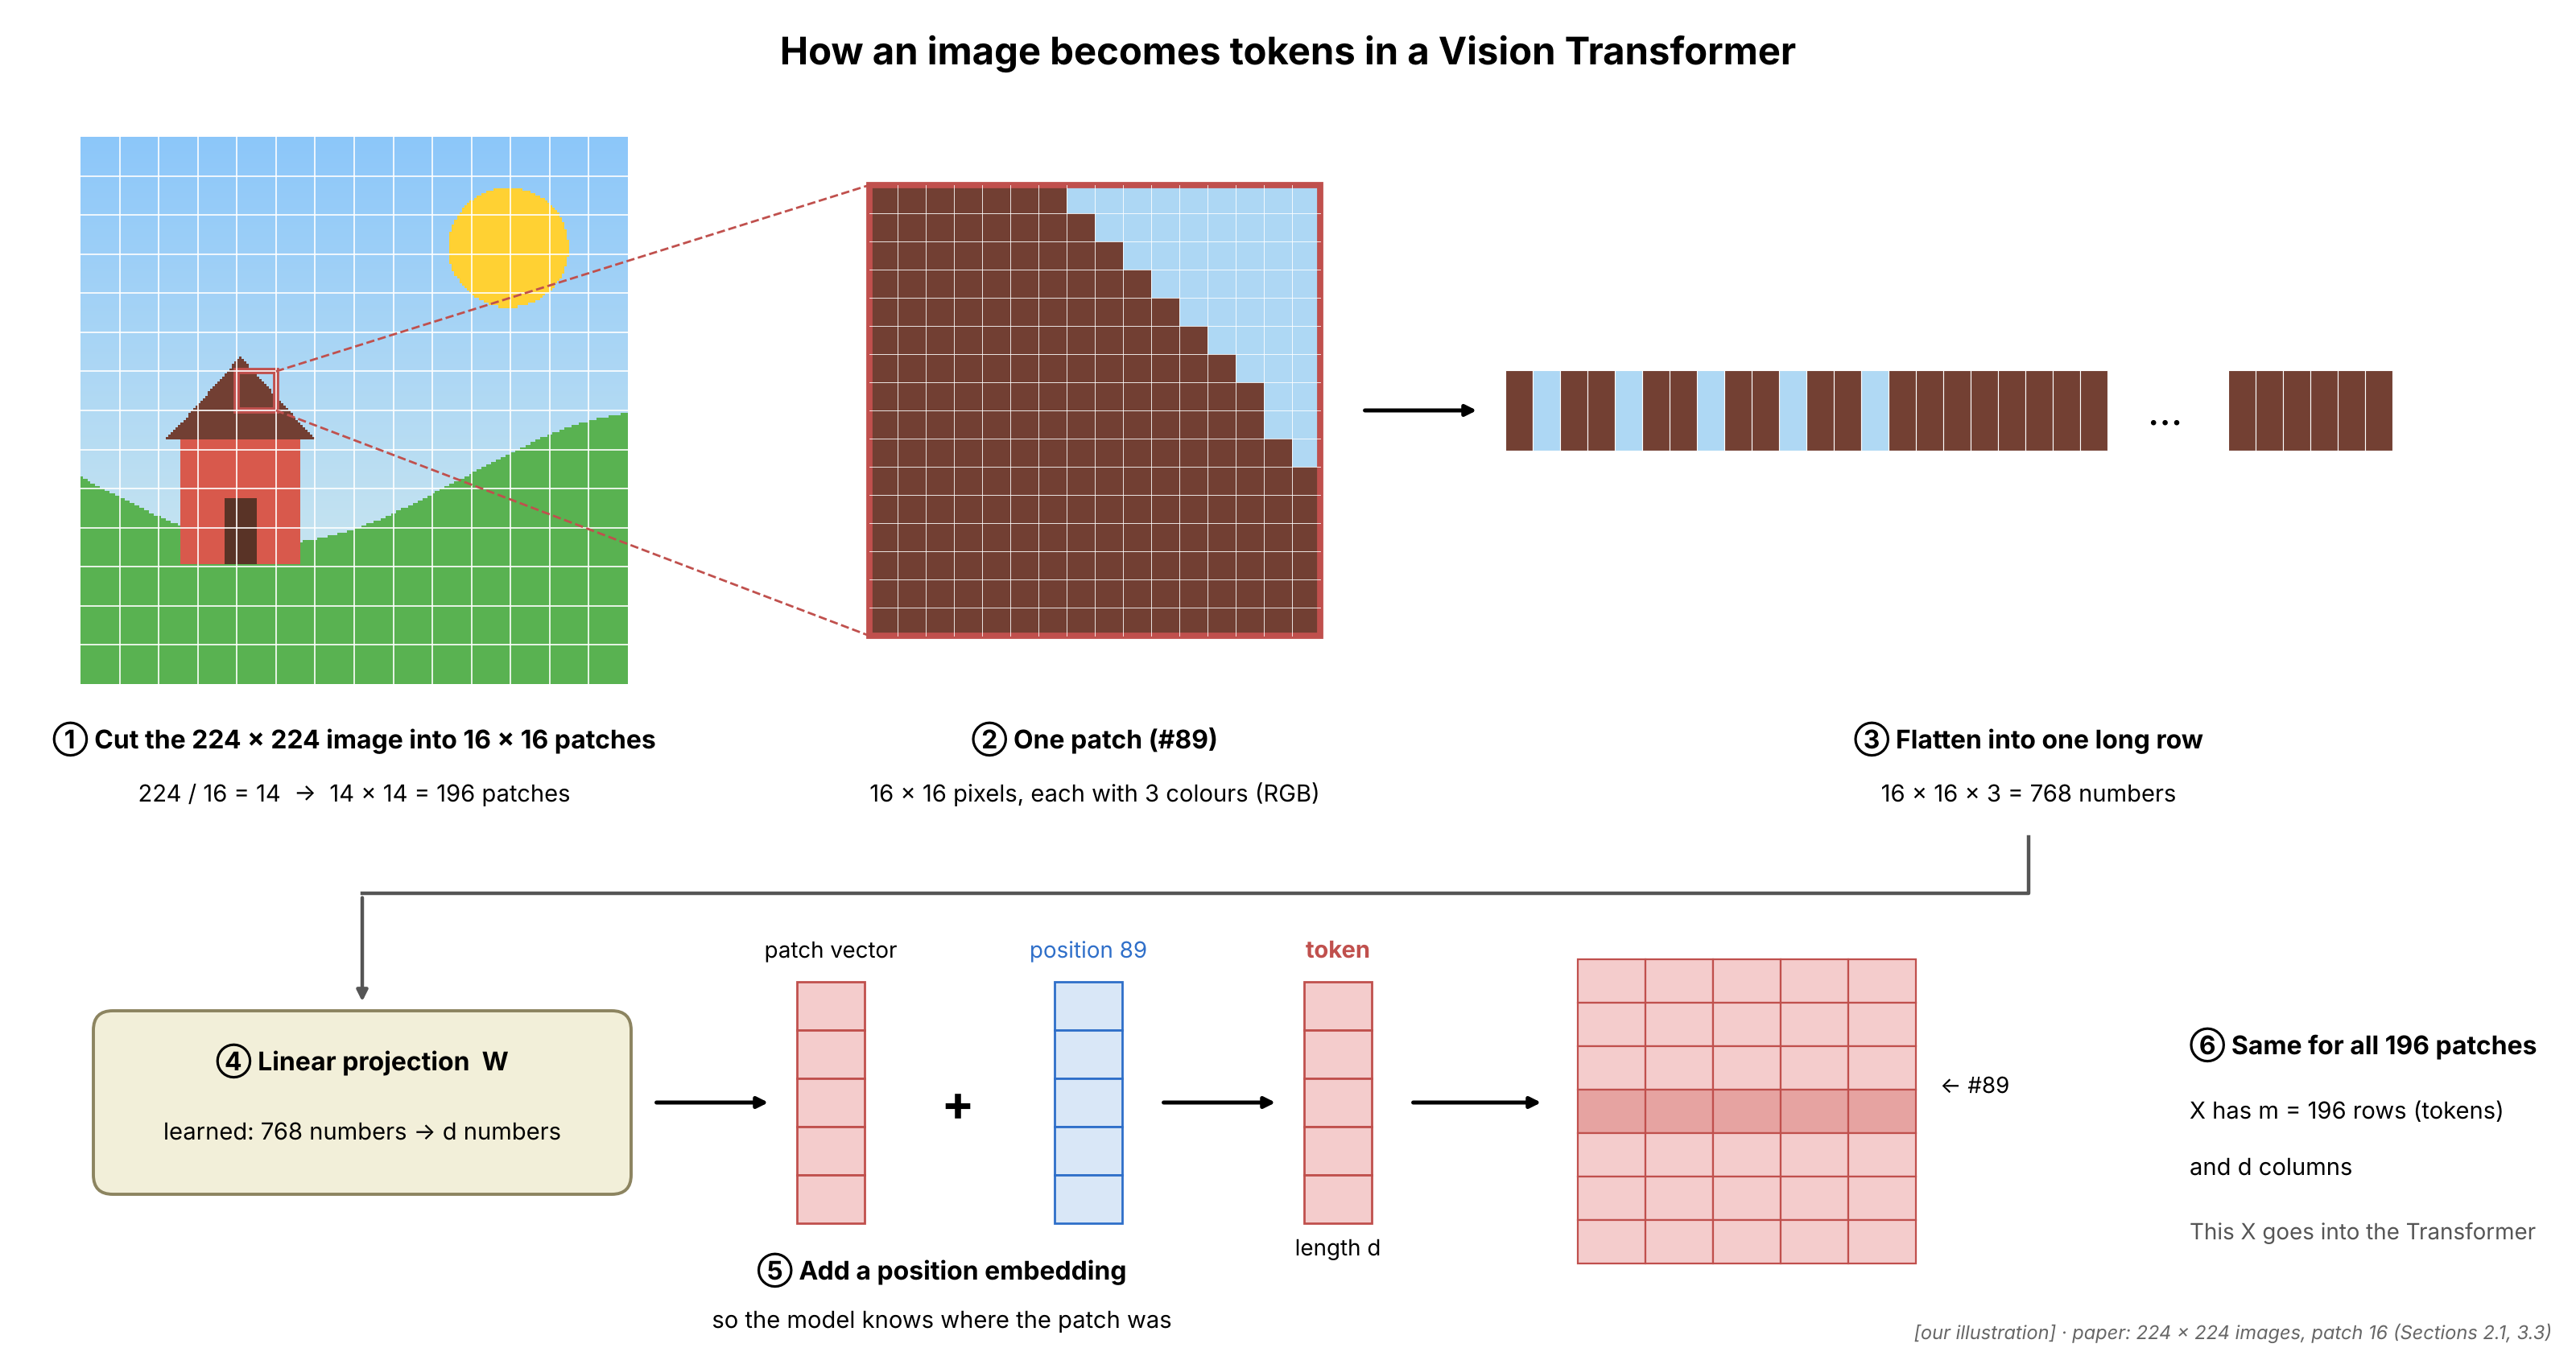

**[our illustration]** The six steps: cut into patches → take one patch → flatten (768 numbers) → linear projection to d numbers → add a position embedding → stack all 196 tokens into $X$.

**The real numbers:** the paper trains at **224 × 224** (Section 3.3). With 16 × 16 patches:

$$
\frac{224}{16} \times \frac{224}{16} = 14 \times 14 = \boxed{196 \text{ tokens}}
$$

| Patch size | Example model | Tokens at 224 |
|---|---|---|
| 32 | B/32 | 7 × 7 = 49 |
| 16 | B/16 | 14 × 14 = 196 |
| 14 | H/14 | 16 × 16 = 256 |
| 8 | S/8 | 28 × 28 = 784 |

Model names mean **size / patch size**: S = Small, B = Base, L = Large, H = Huge. Smaller patches → more tokens → more compute (attention grows with $m^2$).

**Notation (Section 2.1):**

| Symbol | Meaning |
|---|---|
| $X \in \mathbb{R}^{m \times d}$ | input tokens of **one sequence** (one image) |
| $m$ | number of tokens |
| $d$ | token dimension |
| $n$ | number of experts, $f_i : \mathbb{R}^d \to \mathbb{R}^d$ |

You will see the same patch grid on the duck in Figure 1 (Section 6 of this notebook).

## 5. Sparse MoE: how routing works and what goes wrong

*Paper: Section 1, Section 2.2, Section 3.2. The animations in this section are our illustrations with toy numbers.*

### 5.1 The router, step by step

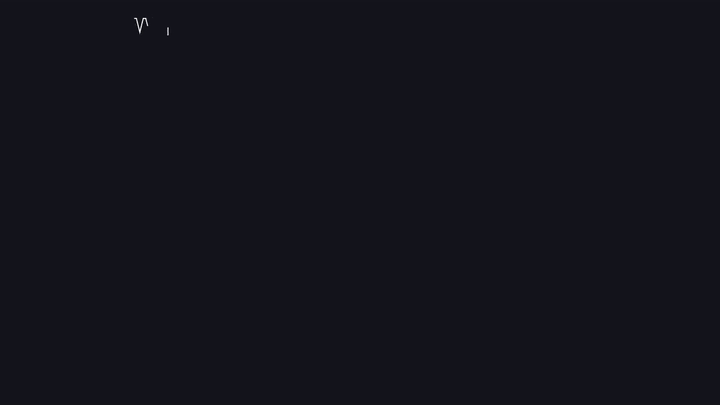

**Animation 2 · What the router computes for one token** *[our illustration, toy numbers]*

1. The router multiplies the token by its weight matrix: $x \cdot W$ gives **one score per expert**.
2. Softmax turns the scores into **probabilities** that sum to 1.
3. **Top-k** keeps only the best expert(s) (here top-1: Expert 2, with 0.62).
4. **Only that expert runs**, and its output is weighted by 0.62: $y = 0.62 \times E_2(x)$.

The paper describes this as "top-k-scored experts" (Section 2.2). The key point is step 3: a **hard yes/no decision**. Experts 1, 3 and 4 learn nothing from this token. As the paper says, routing approaches are *"discrete in nature, and thus non-differentiable"* (Section 2.2).

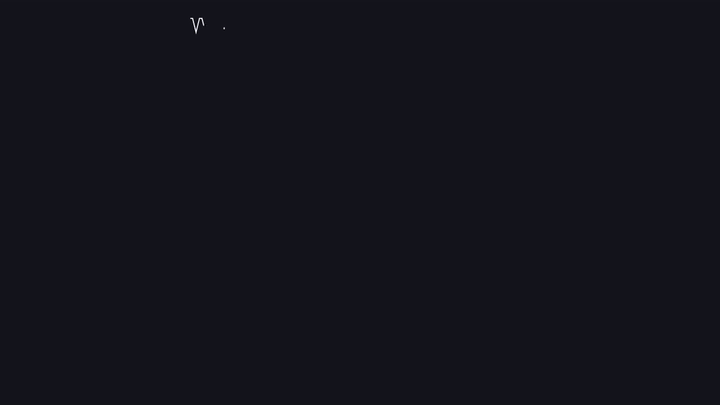

**Animation 3 · Why top-k is not differentiable.** In the same example, raising Expert 3's score changes nothing (flat, gradient 0) until it passes Expert 2, and then the choice jumps. *[our illustration]*

### 5.2 Capacity: every expert has a fixed number of seats

Each expert has a **buffer** with a fixed number of places (its capacity). The paper defines it for Experts Choice (Section 3.2):

$$
E \cdot C = c \cdot T
$$

$E$ = experts, $C$ = places per expert, $T$ = tokens in the group, $c$ = capacity multiplier. With $c = 1$ there are exactly as many places as tokens; the paper tries $c \in \{0.5, 1, 2\}$.

### 5.3 Tokens Choice: each token picks its top-K experts (Sections 2.2, 3.2)

A token goes to its top-K experts **while they still have room**. Used by Shazeer et al. (2017), GShard and V-MoE; the paper's baseline uses K ∈ {1, 2} with Batch Priority Routing (BPR).

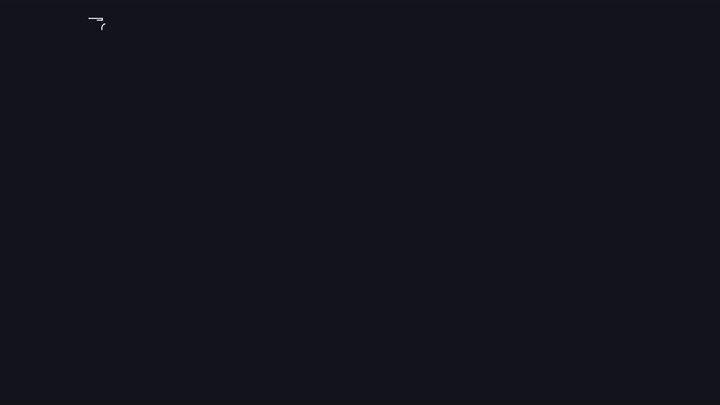

**Animation 4 · Tokens Choice with capacity 2** *[our illustration]*

**What to notice:**
1. Expert 1 is chosen by **4 tokens** but has room for **2**, so t4 and t5 are **dropped**.
2. Experts 2 and 3 are half empty → **expert imbalance**.

### 5.4 Experts Choice: each expert picks its top-C tokens (Sections 2.2, 3.2)

Flip the rule: each **expert** picks its best C tokens. Balance is guaranteed, but even with $c = 1$, "some tokens are simultaneously selected by several experts whereas some other tokens are not selected at all" (Section 3.2).

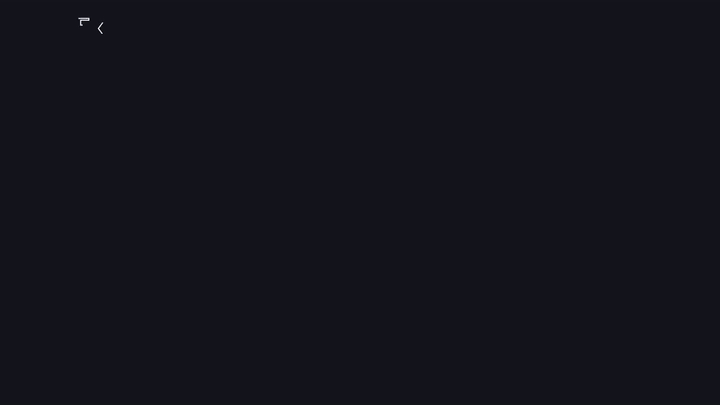

**Animation 5 · Experts Choice with C = 2** *[our illustration]*

**What to notice:**
1. Each column takes its 2 highest scores, so every expert gets exactly 2 tokens → **balanced**.
2. But t2 and t5 are picked **twice**, and t3 and t4 are picked by **no expert** → still **dropping**.

### 5.5 Summary of the problems

| Problem | Tokens Choice | Experts Choice | Paper |
|---|---|---|---|
| **Token dropping** | yes | yes | Section 2.2 |
| **Expert imbalance** | yes | no | Section 2.2 |
| **Discrete routing → not differentiable** | yes | yes | Section 2.2 |
| **Sort / top-k are slow** on accelerators; throughput drops with many experts | yes | yes | Sections 2.2, 3.5 |
| **Batch-level determinism only:** tokens of different images compete for expert buffers | yes | yes | Section 2.2 |

**Bottom line:** every problem comes from one source, the **hard routing decision** in step 3 of the router.

> **Question:** can we keep the benefits of MoE **without** that hard decision? → **Soft MoE**, Part II.

---
# PART II

## 6. Soft MoE: the main idea


Soft MoE does **not** assign each original token to a small set of experts. Instead, it constructs several **slots**. Each slot is a **weighted average of all input token vectors**. The slots are assigned to experts according to a fixed layout; each expert processes a set number of slots. Then the expert outputs are mixed back into output token vectors.

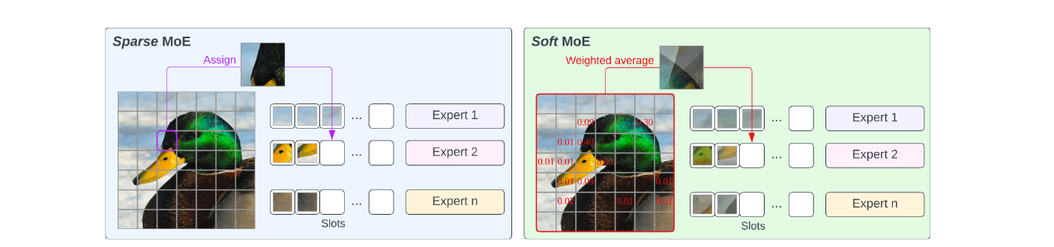

*Figure 1 — Puigcerver et al. (2024), ICLR. Sparse MoE (left) vs Soft MoE (right).*

- **Left (Sparse):** one *selected* image-patch token is assigned to a slot of an expert.
- **Right (Soft):** the **red numbers** (e.g., 0.40, 0.30, 0.01) illustrate **Dispatch weights** for **one particular slot**. Every input patch token has a weight for that slot.
- The **small blurry patch at the top-right** visualizes the weighted mixture from **all** patches. A patch with a higher weight contributes more to that slot's **feature vector**.
- The numbers tell us **how strongly one token's features enter this slot**. Higher weight means higher compatibility according to the learned slot-routing scores.



## 7. The Soft MoE algorithm, step by step

The pipeline is:

**Input tokens** $X$ → **routing logits** $L$ → **dispatch weights** $D$ → **input slots** $\tilde X$ → **expert MLPs** → **output slots** $\tilde Y$ → **combine weights** $C$ → **output tokens** $Y$.



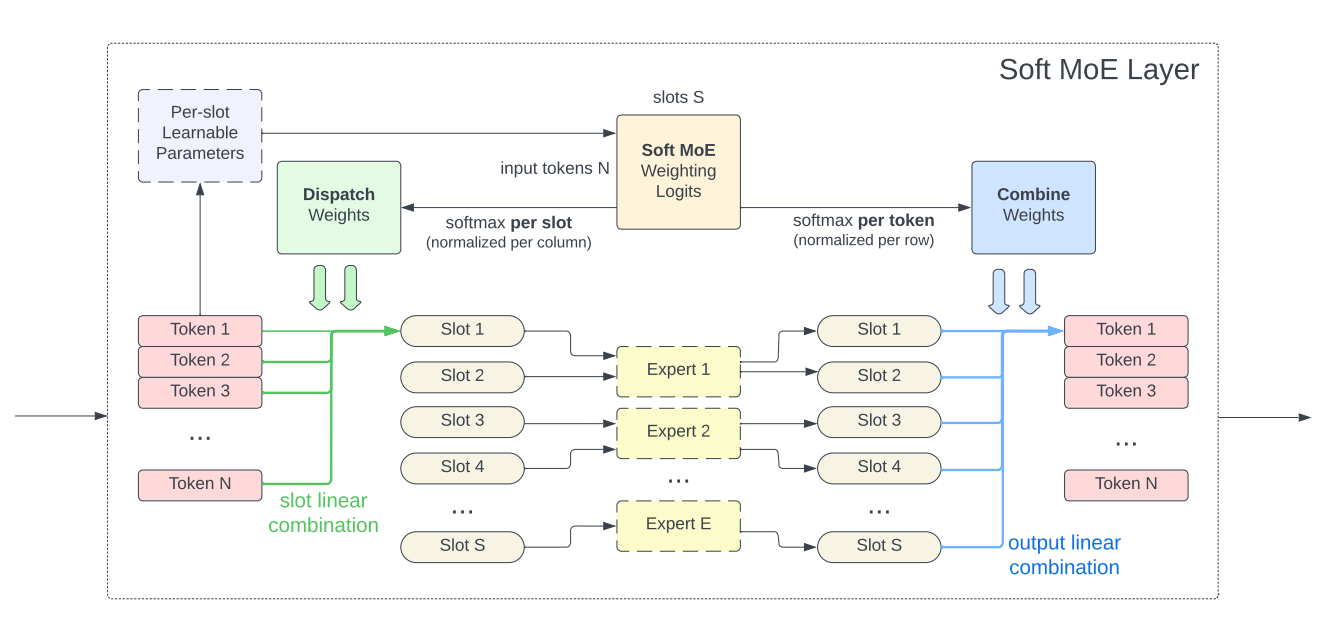
*Figure 2 — Puigcerver et al. (2024), ICLR. Soft MoE routing details.*


The figure illustrates the complete routing process of a **Soft Mixture of Experts (Soft MoE)** layer. Instead of assigning individual tokens directly to experts, Soft MoE creates weighted combinations of input tokens called **slots**. These slots are processed by experts, and their outputs are combined to produce the final output tokens.

### Step-by-Step Explanation

**1. Input Tokens (X)**

The layer receives a sequence of input tokens from the Transformer. Each token is a feature vector representing information from the input, such as an image patch.

**2. Per-Slot Learnable Parameters (Φ)**

Each slot has its own learnable parameter vector. These parameters are learned during training and are used to determine how strongly each input token contributes to each slot.

**3. Soft MoE Weighting Logits**

Soft MoE computes a compatibility score between every input token and every slot:

$$
L = X\Phi
$$

Here, **X** contains the input token vectors, **Φ** contains the learnable slot parameters, and **L** is the resulting matrix of token–slot compatibility scores, called *logits*.

The same logits are used to compute both Dispatch and Combine weights.

**4. Dispatch Weights (Green — Tokens → Slots)**

Dispatch determines how much each input token contributes to each input slot.

First, a softmax is applied **over the input tokens for each slot** (column-wise normalization):

$$
D_{ij} =
\frac{\exp((X\Phi)_{ij})}
{\sum_{i'=1}^{m}\exp((X\Phi)_{i'j})}
$$

Then, the input slots are constructed:

$$
\widetilde{X}=D^\top X
$$

**Explanation:**

- **Dᵢⱼ:** The contribution weight of input token *i* to slot *j*.
- **(XΦ)ᵢⱼ:** The compatibility score between token *i* and slot *j*.
- **m:** Total number of input tokens.
- **D:** The dispatch weights matrix.
- **Dᵀ:** Transpose of the dispatch matrix.
- **X̃:** The resulting input slot vectors.

Each input token vector is multiplied by its corresponding dispatch weight, and the weighted vectors are summed to form an **Input Slot Vector**.

Therefore, each slot is a **weighted average of all input tokens**, rather than a single selected token. The dispatch weights for each slot sum to 1.

**5. Experts — Processing the Slots**

The input slots are assigned to experts in a fixed, round-robin arrangement. Each expert receives a predefined number of slots.

Each expert is typically an MLP with its own learnable parameters. It processes its assigned input slots and transforms them into **Output Slots (Ỹ)**.

This allows different experts to learn different feature transformations.

**6. Combine Weights (Blue — Slots → Tokens)**

Combine determines how much each output slot contributes to each final output token.

The same logits are used, but softmax is now applied **over the slots for each input token** (row-wise normalization):

$$
C_{ij} =
\frac{\exp((X\Phi)_{ij})}
{\sum_{j'=1}^{n\cdot p}\exp((X\Phi)_{ij'})}
$$

Then, the output tokens are constructed:

$$
Y=C\widetilde{Y}
$$

**Explanation:**

- **Cᵢⱼ:** The contribution weight of output slot *j* to output token *i*.
- **n:** Number of experts.
- **p:** Number of slots per expert.
- **n × p:** Total number of slots.
- **C:** The combine weights matrix.
- **Ỹ:** The output slots produced by the experts.
- **Y:** The final output token representations.

Each output slot vector is multiplied by its corresponding combine weight, and the weighted vectors are summed to produce an **Output Token**.

As a result, the layer restores the original number of tokens, but their feature representations have been updated through expert processing.

### Key Difference Between Dispatch and Combine

| Dispatch Weights (D) | Combine Weights (C) |
|---|---|
| Input Tokens → Input Slots | Output Slots → Output Tokens |
| Softmax over tokens (columns) | Softmax over slots (rows) |
| Constructs the input for each expert | Constructs the output for each token |
| Each slot mixes all input tokens | Each output token mixes all output slots |


## 8. Worked example

This example uses 3 input tokens, 2 expert, and 1 slot per expert.

First, Soft MoE computes a token–slot compatibility matrix, called the logits (L = XΦ).

**Setup:** 3 tokens, 2 experts, 1 slot per expert ($m = 3,\; n = 2,\; p = 1$).

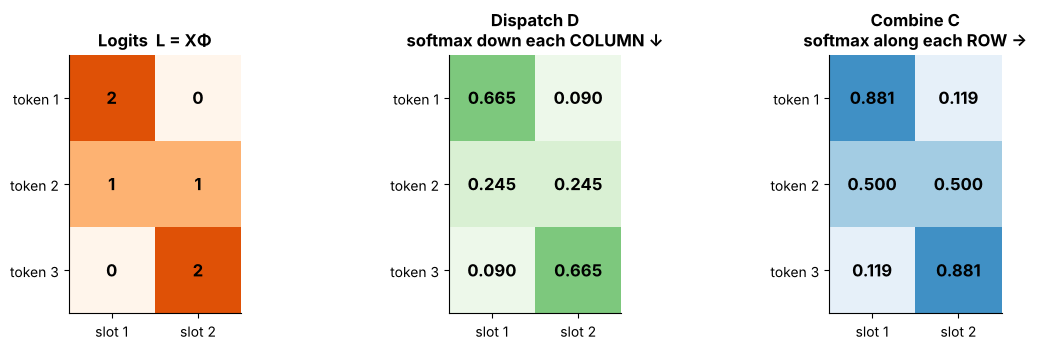

1. Dispatch (softmax down each column)

For Slot 1:

e² = 7.389, e¹ = 2.718, e⁰ = 1

Sum = 11.107

The dispatch weights are used to create the input slots:

Slot 1 = 0.665x₁ + 0.245x₂ + 0.090x₃

Slot 2 = 0.090x₁ + 0.245x₂ + 0.665x₃

Each input slot is a weighted average of all three input token vectors.

2. Expert Processing

Each expert processes its assigned input slot:

Output Slot 1: ỹ₁ = E₁(Slot 1)

Output Slot 2: ỹ₂ = E₂(Slot 2)

Each expert applies its own learned transformation to produce an output slot.

3. Combine (softmax along each row)

The combine weights are used to reconstruct the output tokens:

y₁ = 0.881ỹ₁ + 0.119ỹ₂

y₂ = 0.500ỹ₁ + 0.500ỹ₂

y₃ = 0.119ỹ₁ + 0.881ỹ₂

Each output token is a weighted average of the two processed output slots.

## 9. Properties of Soft MoE


| Property | Why it holds |
|---|---|
| **Fully differentiable** | Uses softmax and weighted averages instead of hard token-to-expert assignments, allowing gradients to flow through the routing process. |
| **No token dropping or expert imbalance** | Every token contributes to all slots, and each expert processes exactly **p slots**. |
| **Fast** | Avoids sorting and top-k operations. The main expert computation depends on the total number of slots. |
| **Features of both sparse and dense** | Every token contributes to all slots, but each expert processes only its assigned slots instead of all input tokens individually. |
| **Per-sequence determinism** | Each sequence is processed independently, so its routing does not depend on other sequences competing for expert capacity. |





---
# PART III


## 10. Experimental Setup

*Source: Paper, Sections 3.1–3.4.*

- **Task:** Image classification using Vision Transformers (ViTs).
- **Pre-training data:** JFT-4B, a dataset containing over 4 billion images across 29,000 classes.
- **Architecture:** Soft MoE replaces the MLP layers in the second half of the Transformer blocks.
- **Baselines:** Dense ViTs, Token Choice MoE, and Expert Choice MoE.

**Evaluation Metrics:**

- **JFT Precision@1:** Measures top-1 classification accuracy on the JFT validation set.
- **ImageNet 10-shot:** Evaluates learned representations by freezing the pretrained model and training a new classification head using only 10 labeled images per class.
- **ImageNet Fine-tuning:** Measures accuracy after fine-tuning the pretrained model on ImageNet-1k.

**Experimental Settings:**

- **Training efficiency:** 106 model configurations were trained for 300K steps to compare accuracy against training cost (Figure 3).
- **Long-training experiments:** Selected models were trained for longer durations to evaluate accuracy and inference efficiency (Table 1).

**Goal:** Evaluate whether Soft MoE improves model accuracy and efficiency compared with dense and sparse MoE architectures.


## 11. Main results

*Source: paper, Table 1, Figure 3 and Sections 3.3–3.4.*

### Table 1 — long-trained models

| Model | Params | Train TPU-days | Inference (ms/img) | GFLOP/img | JFT P@1 | IN 10-shot | IN fine-tune |
|---|---|---|---|---|---|---|---|
| ViT-H/14 (1M steps) | 669M | 1019.9 | 8.6 | 334.2 | 58.8 | 82.7 | 88.6 |
| ViT-H/14 (2M steps) | 669M | 2039.8 | 8.6 | 334.2 | 59.7 | 83.3 | 88.9 |
| Soft MoE-S/14, 256 experts | 1.8B | 494.7 | 0.9 | 13.2 | 60.1 | 80.6 | 87.5 |
| **Soft MoE-B/16, 128 experts** | 3.7B | 1011.4 | **1.5** | **32.0** | 62.4 | 82.9 | 88.5 |
| **Soft MoE-L/16, 128 experts** | 13.1B | 1355.4 | 4.8 | 111.1 | **63.0** | **84.3** | **89.2** |

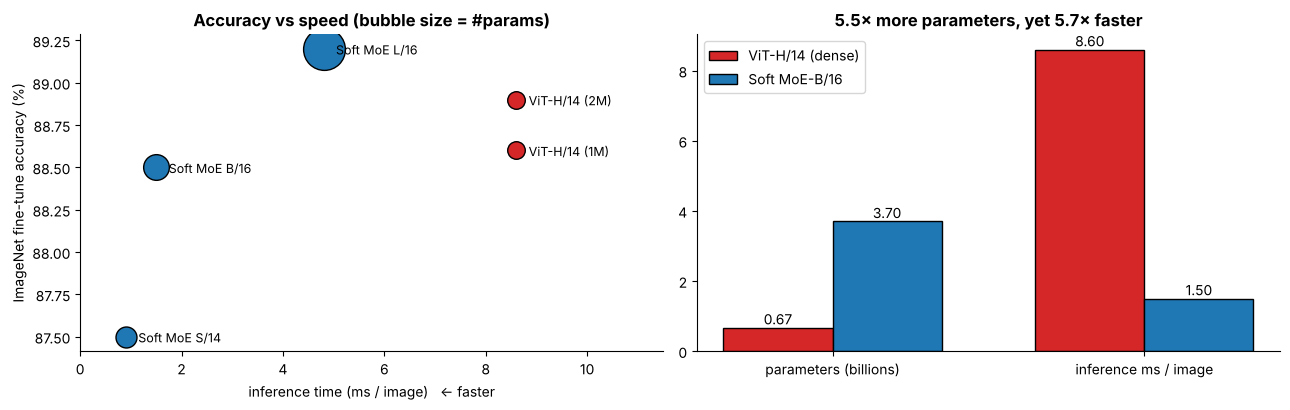


**What to Notice:**

1. **Soft MoE-B/16 vs. ViT-H/14:** At a similar training cost (~1,000 TPUv3-days), Soft MoE-B/16 achieves higher JFT accuracy (62.4% vs. 58.8%) and comparable ImageNet results. Despite having 5.5× more parameters, it is approximately 5.7× faster at inference and requires about 10.4× fewer inference FLOPs.

2. **Soft MoE-L/16:** Achieves the highest accuracy among the models listed in Table 1 across all three evaluation metrics (63.0% JFT, 84.3% ImageNet 10-shot, and 89.2% ImageNet fine-tuning), while being approximately 1.8× faster at inference than ViT-H/14.

3. **Scaling Model Capacity:** The paper's abstract also reports a larger Soft MoE-H/14 model with over 40× more parameters than ViT-H/14, but only 2% higher inference time.

4. **Training Efficiency (Figure 3):** The training Pareto frontiers show that Soft MoE achieves a better accuracy–cost trade-off than the evaluated dense and sparse MoE baselines across the tested training budgets.

**Key Insight:** Soft MoE can increase model capacity while maintaining competitive computational efficiency.


### Figure 3 — Training Pareto Frontiers

Figure 3 compares the accuracy and training cost of Soft MoE, dense ViTs, and sparse MoE models across different model configurations.

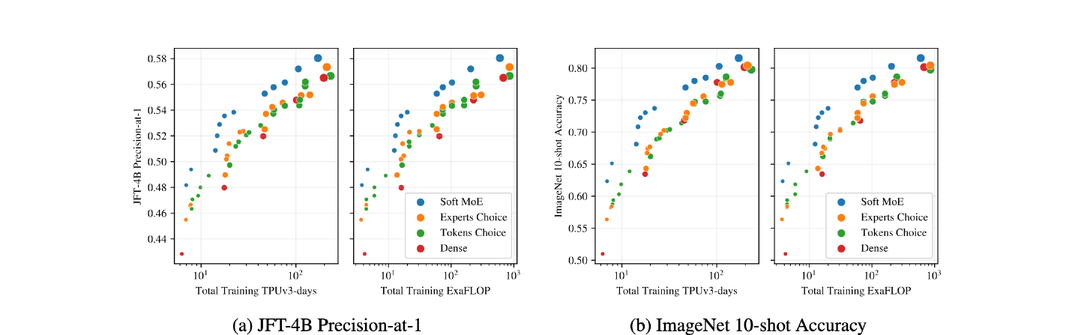

*Figure 3 — Puigcerver et al. (2024), ICLR. Training Pareto frontiers: (a) JFT-4B precision@1, (b) ImageNet 10-shot accuracy.*


**How to Read Figure 3:**

- **X-axis:** Training cost, measured in TPUv3-days or exaFLOPs.
- **Y-axis:** Model accuracy on JFT-4B or ImageNet 10-shot.
- **Dot size:** Represents model size.
- **Blue dots:** Soft MoE models.
- **Other colors:** Dense ViT, Token Choice, and Expert Choice models.

**Observation:** Across the evaluated model configurations and training budgets, Soft MoE achieves a better accuracy–cost trade-off than the tested dense and sparse MoE baselines.

**Takeaway:** Soft MoE improves training efficiency, achieving higher accuracy for comparable computational budgets in the experiments reported in the paper.


## 12. Is the learned routing really what helps? (Ablation)

*Source: Paper, Sections 3.5–3.6, Figure 6 and Table 2.*


**Research Question:** Does Soft MoE perform better because of its learned routing mechanism, or simply because it has more parameters?

To investigate this, the authors compare different routing strategies using Soft MoE-S/14 with 256 experts, trained for 300K steps. A dense ViT is included as a separate baseline.

**Routing Variants:**

- **Soft MoE:** Both dispatch and combine weights are learned.
- **Soft / Uniform:** Learned dispatch with uniform combine weights.
- **Uniform / Soft:** Uniform dispatch with learned combine weights.
- **Uniform:** Both dispatch and combine use uniform averaging.
- **Identity:** Tokens are assigned to experts without learned token mixing.
- **Dense ViT:** Baseline without MoE experts.

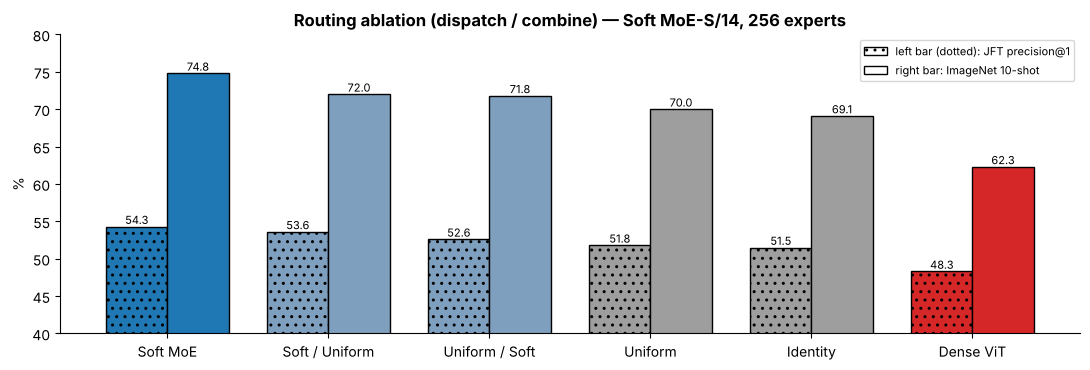


**What to Notice:**

1. **Learned routing performs best:** Full Soft MoE achieves the highest ImageNet 10-shot accuracy (74.8%).

2. **Model capacity also matters:** Uniform and Identity routing outperform the dense ViT baseline, suggesting that the additional expert capacity contributes to performance.

3. **Learning both routing stages is beneficial:** Full Soft MoE outperforms variants with only learned dispatch or only learned combine weights.

4. **Dispatch vs. Combine:** Soft / Uniform achieves 72.0%, while Uniform / Soft achieves 71.8%. This suggests a slightly larger contribution from learned dispatch in this experiment, although the difference is small.

**Takeaway:** The improvement comes from both additional expert capacity and the learned soft routing mechanism. The full routing approach achieves the strongest performance.


### Number of slots and experts

![Figure 6 of the paper: performance for different numbers of experts and slots per token, and training throughput](https://arxiv.org/html/2308.00951v2/softmoe_num_slots_per_token_vs_num_experts.png)

*Figure 6 from Puigcerver et al. (2024). Top: ImageNet performance for different numbers of experts (columns) and slots per token (rows). Bottom: training throughput.*

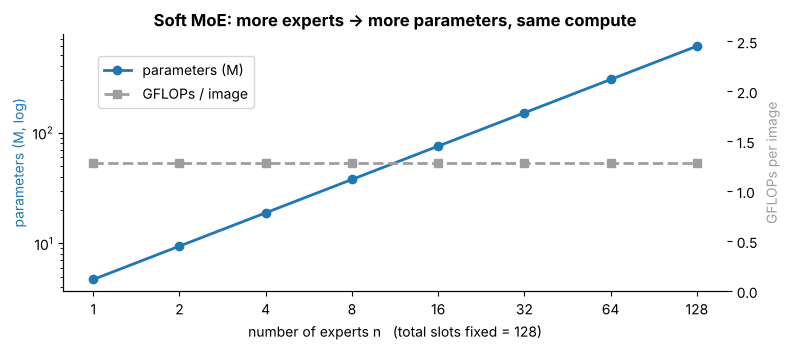


*Our illustration: Conceptual scaling trend with a fixed total of 128 slots. This is not an experimental result reported in the paper.*

**What to Notice:**

1. **Scaling Experts:** When the total number of slots is fixed, increasing the number of experts increases model capacity without proportionally increasing expert-processing FLOPs.

2. **One Slot per Expert:** The paper finds that using more experts with fewer slots per expert generally produces better results than using fewer experts with multiple slots each.

3. **Training Throughput:** Soft MoE maintains relatively stable training throughput as the number of experts increases, while the evaluated sparse MoE methods experience significant slowdowns at large expert counts.

**Takeaway:** Soft MoE enables effective scaling of model capacity while maintaining relatively stable computational cost, although parameter memory and implementation overhead still matter.



## 13. Limitations and Final Summary

*Source: Paper, Sections 2.2 and 6.*

### Limitations

| Limitation | Explanation |
|---|---|
| **Autoregressive Decoding** | Soft MoE mixes information from all input tokens, potentially including future tokens. This makes preserving causality difficult in autoregressive language models. |
| **Memory Consumption** | Increasing the number of experts increases the total number of parameters, which can require substantial memory even when computational cost remains relatively low. |
| **Lazy Experts** | The authors hypothesize that multiple slots processed by the same expert may become similar, providing limited additional information. This helps explain why one slot per expert often works better. |


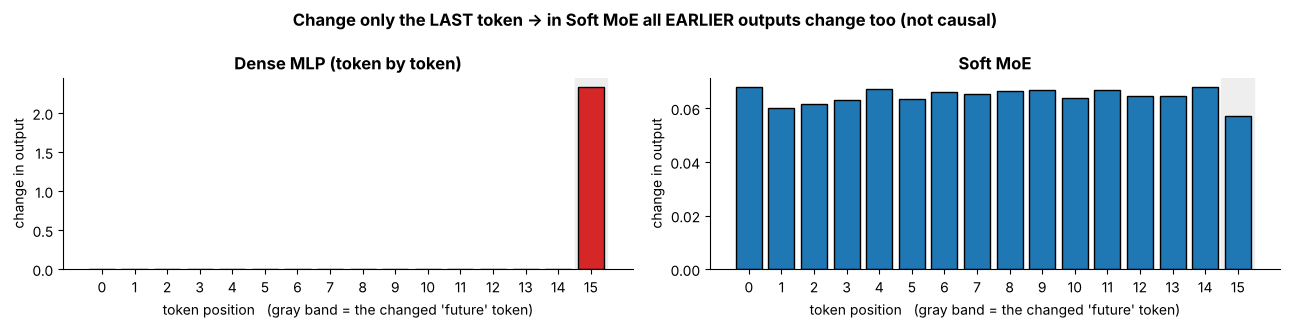


**Bottom Line:** Soft MoE demonstrates strong performance in vision encoders, but extending the proposed routing mechanism directly to autoregressive language models remains challenging because causal information flow must be preserved.



### Sparse vs Soft MoE

| Property | Dense ViT | Sparse MoE | Soft MoE |
|---|---|---|---|
| **Expert inputs** | Not applicable | Original tokens | Weighted mixtures of tokens (slots) |
| **Routing mechanism** | No expert routing | Discrete token-to-expert assignments | Continuous soft routing |
| **Token dropping** | No | May occur, depending on the routing method | No |
| **Load-balancing loss** | Not needed | Often used, method-dependent | Not needed |
| **Routing differentiability** | Not applicable | Hard assignment decisions are discrete | Fully differentiable |
| **Causal decoding** | Not applicable to this ViT; supported by causal dense Transformers | Supported by causal sparse MoE implementations | Not directly supported by the proposed method |




### Final Takeaway

**1. Core Idea**

Soft MoE replaces hard token-to-expert assignments with continuous, differentiable routing through learned dispatch and combine weights.

**2. Experimental Findings**

The experiments demonstrate improved accuracy–efficiency trade-offs compared with the evaluated dense and sparse MoE baselines, especially in large-scale vision models.

**3. Limitations**

However, challenges remain, including autoregressive decoding, memory requirements, and potentially redundant expert slots.

---

**Key Message:** Soft MoE can increase model capacity through more experts without a proportional increase in expert computation, when the total number of slots is kept fixed.



# References

1. Puigcerver, J., Riquelme, C., Mustafa, B., & Houlsby, N. (2024). *From Sparse to Soft Mixtures of Experts.* ICLR 2024. [PDF](https://proceedings.iclr.cc/paper_files/paper/2024/file/79fea214543ba263952ac3f4e5452b14-Paper-Conference.pdf)
2. Jacobs, R. A., Jordan, M. I., Nowlan, S. J., & Hinton, G. E. (1991). *Adaptive Mixtures of Local Experts.* Neural Computation, 3(1).
3. Shazeer, N., et al. (2017). *Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer.* ICLR 2017.
4. Lepikhin, D., et al. (2021). *GShard: Scaling Giant Models with Conditional Computation and Automatic Sharding.* ICLR 2021.
5. Fedus, W., Zoph, B., & Shazeer, N. (2022). *Switch Transformers.* JMLR.
6. Riquelme, C., et al. (2021). *Scaling Vision with Sparse Mixture of Experts (V-MoE).* NeurIPS 2021.
7. Zhou, Y., et al. (2022). *Mixture-of-Experts with Expert Choice Routing.* NeurIPS 2022.
8. Sanseviero, O., Tunstall, L., Schmid, P., Mangrulkar, S., Belkada, Y., & Cuenca, P. (2023, December 11). *Mixture of Experts Explained.* Hugging Face Blog. https://huggingface.co/blog/moe



**Note on figures and results:**

- Figures 1, 2, and 3 are taken from the original paper and credited where they appear.
- Figure 6 is sourced from the arXiv HTML version of the paper and requires an internet connection to display.
- Other visualizations are our own illustrations, created to explain concepts or visualize results from the paper.
- The numerical results in Section 12 are taken from Table 1 of the paper.
- The ablation results in Section 13 are taken from Table 2, while the expert-scaling analysis is based on Figure 6.
- Conceptual illustrations are not original experimental results from the paper.
